<a href="https://colab.research.google.com/github/192521497simats-bot/aswatha-ITA0312-MOBILE-COMPUTING/blob/assignment-2/mobile_comp_assign_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

STORE-AND-FORWARD VS IMMEDIATE TRANSMISSION
 Link Availability (%)  Total Messages  Immediate Delivered  Immediate Lost  Immediate Success Rate (%)  Store-Forward Delivered  Store-Forward Failed  Store-Forward Success Rate (%)  Average Retry Delay (slots)
                  90.0            1000                  902              98                        90.2                     1000                     0                           100.0                         0.11
                  60.0            1000                  592             408                        59.2                     1000                     0                           100.0                         0.71
                  30.0            1000                  307             693                        30.7                     1000                     0                           100.0                         2.28

CSV files generated successfully:
1. q1_summary_results.csv
2. q1_raw_results.csv


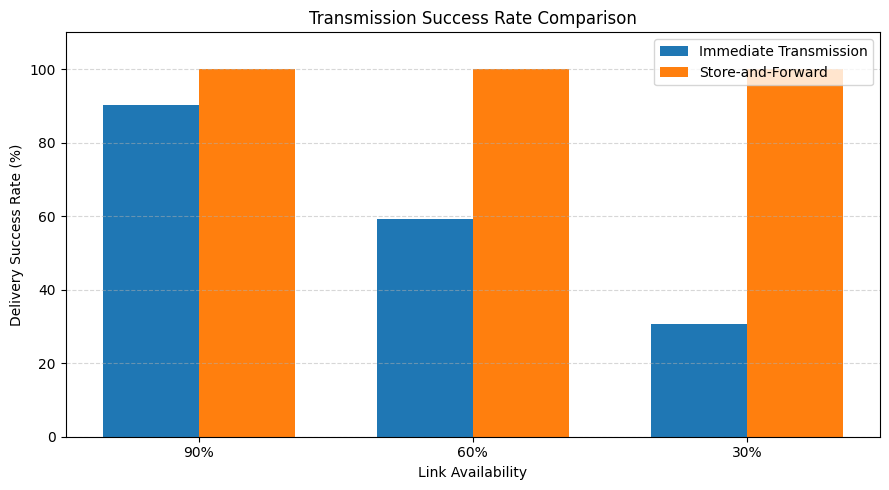

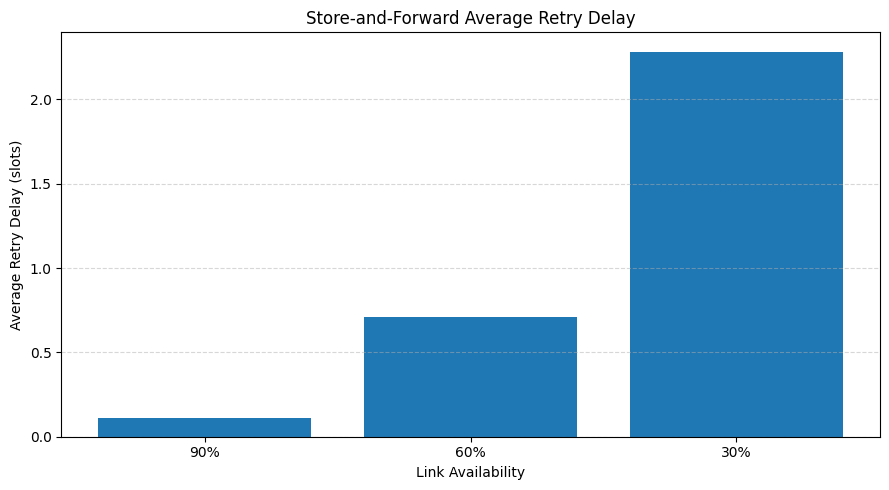


Simulation completed successfully!


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# QUESTION 1: STORE-AND-FORWARD VS IMMEDIATE TRANSMISSION

# Simulation parameters
NUM_MESSAGES = 1000
LINK_AVAILABILITY = [0.90, 0.60, 0.30]
MAX_ATTEMPTS = 1000
RANDOM_SEED = 42

# Fixed random seed for reproducibility
rng = np.random.default_rng(RANDOM_SEED)

summary_results = []
raw_results = []

# Perform simulation for each availability level
for availability in LINK_AVAILABILITY:

    # Number of attempts required for each message
    # Geometric distribution models repeated transmission attempts
    attempts = rng.geometric(
        p=availability,
        size=NUM_MESSAGES
    )

    # Immediate transmission:
    # A message succeeds only on its first attempt
    immediate_success = attempts == 1

    immediate_delivered = np.sum(immediate_success)
    immediate_lost = NUM_MESSAGES - immediate_delivered

    # Store-and-forward transmission:
    # Messages are retained and retried until successful,
    # subject to the maximum attempt limit
    store_forward_success = attempts <= MAX_ATTEMPTS

    store_forward_delivered = np.sum(store_forward_success)
    store_forward_failed = NUM_MESSAGES - store_forward_delivered

    # Delay is measured in retry intervals.
    # The first attempt has zero retry delay.
    delays = attempts[store_forward_success] - 1

    average_delay = (
        np.mean(delays) if len(delays) > 0 else 0
    )

    # Save summary results
    summary_results.append({
        "Link Availability (%)": availability * 100,
        "Total Messages": NUM_MESSAGES,
        "Immediate Delivered": immediate_delivered,
        "Immediate Lost": immediate_lost,
        "Immediate Success Rate (%)":
            immediate_delivered / NUM_MESSAGES * 100,
        "Store-Forward Delivered": store_forward_delivered,
        "Store-Forward Failed": store_forward_failed,
        "Store-Forward Success Rate (%)":
            store_forward_delivered / NUM_MESSAGES * 100,
        "Average Retry Delay (slots)": average_delay
    })

    # Save individual message results
    for i in range(NUM_MESSAGES):
        raw_results.append({
            "Availability (%)": availability * 100,
            "Message ID": i + 1,
            "Attempts Required": attempts[i],
            "Immediate Status":
                "Delivered" if immediate_success[i] else "Lost",
            "Store-Forward Status":
                "Delivered" if store_forward_success[i]
                else "Failed",
            "Retry Delay (slots)": attempts[i] - 1
        })

# Convert results into DataFrames
summary_df = pd.DataFrame(summary_results)
raw_df = pd.DataFrame(raw_results)

# Display simulation results
print("=" * 65)
print("STORE-AND-FORWARD VS IMMEDIATE TRANSMISSION")
print("=" * 65)
print(summary_df.round(2).to_string(index=False))

# Save CSV files
summary_df.to_csv("q1_summary_results.csv", index=False)
raw_df.to_csv("q1_raw_results.csv", index=False)

print("\nCSV files generated successfully:")
print("1. q1_summary_results.csv")
print("2. q1_raw_results.csv")

# Plot 1: Delivery success rate comparison
x = np.arange(len(LINK_AVAILABILITY))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    summary_df["Immediate Success Rate (%)"],
    width,
    label="Immediate Transmission"
)

plt.bar(
    x + width / 2,
    summary_df["Store-Forward Success Rate (%)"],
    width,
    label="Store-and-Forward"
)

plt.xticks(x, ["90%", "60%", "30%"])
plt.xlabel("Link Availability")
plt.ylabel("Delivery Success Rate (%)")
plt.title("Transmission Success Rate Comparison")
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("q1_delivery_comparison.png", dpi=300)
plt.show()

# Plot 2: Average retry delay
plt.figure(figsize=(9, 5))

plt.bar(
    ["90%", "60%", "30%"],
    summary_df["Average Retry Delay (slots)"]
)

plt.xlabel("Link Availability")
plt.ylabel("Average Retry Delay (slots)")
plt.title("Store-and-Forward Average Retry Delay")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("q1_retry_delay.png", dpi=300)
plt.show()

print("\nSimulation completed successfully!")


FDMA AND TDMA CAPACITY CALCULATIONS

FDMA:
Nominal channels: 80
Control channels reserved: 2
Usable traffic channels: 78
Guard band per channel: 2 kHz
Payload efficiency: 92.0 %
Effective channel equivalents: 71.76

TDMA:
Nominal channels: 80
Carriers: 10
Time slots per carrier: 8
Usable traffic slots: 70
Guard time: 5 %
Payload efficiency: 95.0 %
Effective channel equivalents: 66.5

FDMA VS TDMA SIMULATION RESULTS
             Scenario Technique  Total Requests  Accepted Requests  Blocked Requests  Blocking (%)  Allocated Utilization (%)  Active Utilization (%)  Idle Allocated Capacity (%)  Unoccupied Capacity (%)  Effective Payload Utilization (%)
     Continuous Voice      FDMA             411                411                 0          0.00                      34.12                   34.12                         0.00                    65.88                              31.39
     Continuous Voice      TDMA             411                411                 0          0.00     

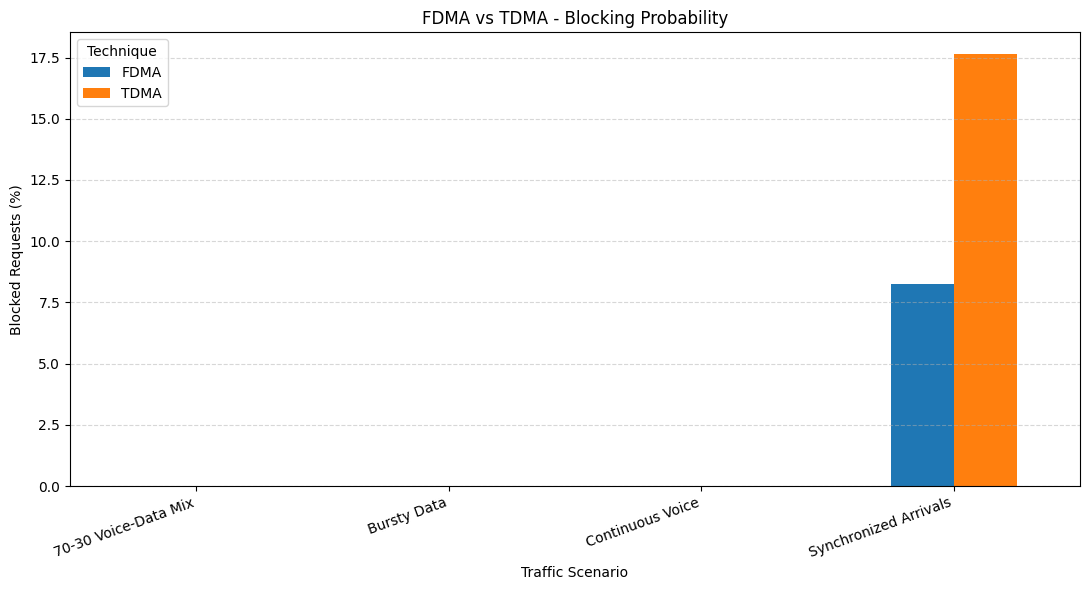

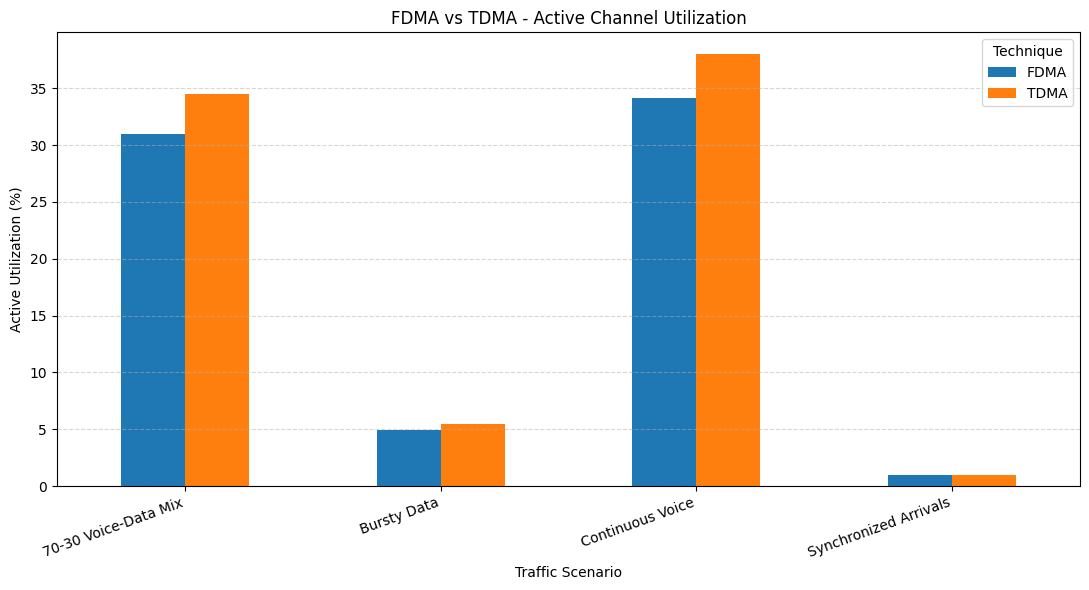

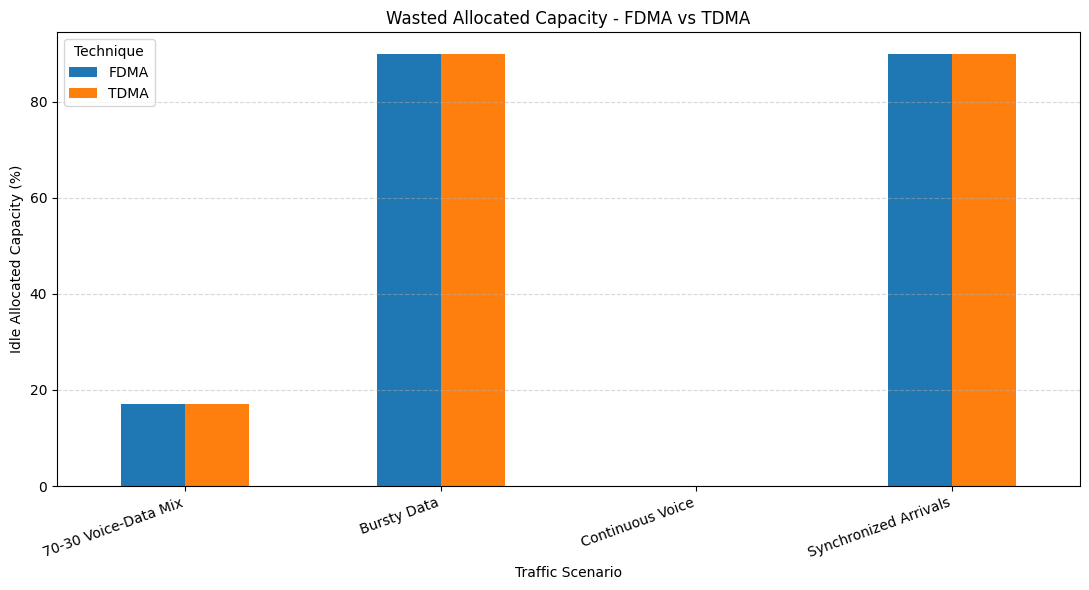


All Question 2 simulations completed successfully!


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# QUESTION 2: FDMA VS TDMA UNDER DIFFERENT TRAFFIC CONDITIONS
# ==========================================================

# 1. SIMULATION PARAMETERS

RANDOM_SEED = 42
SIMULATION_TIME = 1800  # seconds
rng = np.random.default_rng(RANDOM_SEED)

# 2. CAPACITY AND OVERHEAD CALCULATIONS

TOTAL_BANDWIDTH_KHZ = 2000

# FDMA
FDMA_CHANNEL_WIDTH_KHZ = 25
FDMA_NOMINAL_CHANNELS = TOTAL_BANDWIDTH_KHZ // FDMA_CHANNEL_WIDTH_KHZ
FDMA_CONTROL_CHANNELS = 2
FDMA_USABLE_CHANNELS = FDMA_NOMINAL_CHANNELS - FDMA_CONTROL_CHANNELS

FDMA_GUARD_KHZ = 2
FDMA_PAYLOAD_EFFICIENCY = (
    FDMA_CHANNEL_WIDTH_KHZ - FDMA_GUARD_KHZ
) / FDMA_CHANNEL_WIDTH_KHZ

# TDMA
TDMA_CARRIER_WIDTH_KHZ = 200
TDMA_SLOTS_PER_CARRIER = 8
TDMA_CARRIERS = TOTAL_BANDWIDTH_KHZ // TDMA_CARRIER_WIDTH_KHZ

TDMA_NOMINAL_CHANNELS = (
    TDMA_CARRIERS * TDMA_SLOTS_PER_CARRIER
)

TDMA_CONTROL_SLOTS_PER_CARRIER = 1
TDMA_USABLE_CHANNELS = TDMA_CARRIERS * (
    TDMA_SLOTS_PER_CARRIER - TDMA_CONTROL_SLOTS_PER_CARRIER
)

TDMA_GUARD_TIME_PERCENT = 5
TDMA_PAYLOAD_EFFICIENCY = (
    1 - TDMA_GUARD_TIME_PERCENT / 100
)

print("=" * 65)
print("FDMA AND TDMA CAPACITY CALCULATIONS")
print("=" * 65)

print("\nFDMA:")
print("Nominal channels:", FDMA_NOMINAL_CHANNELS)
print("Control channels reserved:", FDMA_CONTROL_CHANNELS)
print("Usable traffic channels:", FDMA_USABLE_CHANNELS)
print("Guard band per channel:", FDMA_GUARD_KHZ, "kHz")
print("Payload efficiency:", round(FDMA_PAYLOAD_EFFICIENCY * 100, 2), "%")
print("Effective channel equivalents:",
      round(FDMA_USABLE_CHANNELS * FDMA_PAYLOAD_EFFICIENCY, 2))

print("\nTDMA:")
print("Nominal channels:", TDMA_NOMINAL_CHANNELS)
print("Carriers:", TDMA_CARRIERS)
print("Time slots per carrier:", TDMA_SLOTS_PER_CARRIER)
print("Usable traffic slots:", TDMA_USABLE_CHANNELS)
print("Guard time:", TDMA_GUARD_TIME_PERCENT, "%")
print("Payload efficiency:", round(TDMA_PAYLOAD_EFFICIENCY * 100, 2), "%")
print("Effective channel equivalents:",
      round(TDMA_USABLE_CHANNELS * TDMA_PAYLOAD_EFFICIENCY, 2))


# 3. DESIGN FOUR CONTRASTING TRAFFIC DATASETS

def generate_requests(scenario, random_generator):

    requests = []
    request_id = 1

    def add_request(arrival, traffic_type, duration):
        nonlocal request_id

        if traffic_type == "Voice":
            # Voice continuously uses the allocated channel
            activity = np.ones(duration, dtype=int)

        else:
            # Bursty data uses the channel only 10% of the time
            activity = random_generator.binomial(
                1, 0.10, size=duration
            )

        requests.append({
            "Request_ID": request_id,
            "Arrival_Time": arrival,
            "Traffic_Type": traffic_type,
            "Duration": duration,
            "Activity": activity
        })

        request_id += 1

    for second in range(SIMULATION_TIME):

        if scenario == "Continuous Voice":

            # Continuous voice calls
            arrivals = random_generator.poisson(0.22)

            for _ in range(arrivals):
                duration = int(random_generator.integers(90, 151))
                add_request(second, "Voice", duration)

        elif scenario == "Bursty Data":

            # Data traffic with approximately 10% duty cycle
            arrivals = random_generator.poisson(0.65)

            for _ in range(arrivals):
                duration = 60
                add_request(second, "Data", duration)

        elif scenario == "70-30 Voice-Data Mix":

            arrivals = random_generator.poisson(0.30)

            for _ in range(arrivals):

                if random_generator.random() < 0.70:
                    duration = 120
                    add_request(second, "Voice", duration)
                else:
                    duration = 60
                    add_request(second, "Data", duration)

        elif scenario == "Synchronized Arrivals":

            # Edge case: 85 data requests arrive simultaneously
            if second % 300 == 0:

                for _ in range(85):
                    add_request(second, "Data", 30)

    return requests


# 4. SIMULATE DEDICATED CHANNEL ALLOCATION

def simulate_access(requests, capacity, efficiency, technique):

    arrivals_by_time = [[] for _ in range(SIMULATION_TIME)]

    for request in requests:
        arrivals_by_time[request["Arrival_Time"]].append(request)

    active_requests = {}
    outcomes = {}

    blocked = 0
    accepted = 0

    allocated_channel_seconds = 0
    active_channel_seconds = 0

    for second in range(SIMULATION_TIME):

        # Release channels when sessions finish
        finished = [
            request_id
            for request_id, request in active_requests.items()
            if request["Arrival_Time"] + request["Duration"] <= second
        ]

        for request_id in finished:
            del active_requests[request_id]

        # Process new requests
        for request in arrivals_by_time[second]:

            request_id = request["Request_ID"]

            if len(active_requests) < capacity:

                active_requests[request_id] = request
                outcomes[request_id] = "Accepted"
                accepted += 1

            else:

                outcomes[request_id] = "Blocked"
                blocked += 1

        # Count occupied and actively transmitting channels
        allocated_now = len(active_requests)

        active_now = 0

        for request in active_requests.values():

            elapsed = second - request["Arrival_Time"]
            active_now += request["Activity"][elapsed]

        allocated_channel_seconds += allocated_now
        active_channel_seconds += active_now

    total_requests = len(requests)

    allocation_utilization = (
        allocated_channel_seconds /
        (capacity * SIMULATION_TIME) * 100
    )

    active_utilization = (
        active_channel_seconds /
        (capacity * SIMULATION_TIME) * 100
    )

    blocking_percentage = (
        blocked / total_requests * 100
        if total_requests > 0 else 0
    )

    idle_allocated_percentage = (
        (allocated_channel_seconds - active_channel_seconds) /
        allocated_channel_seconds * 100
        if allocated_channel_seconds > 0 else 0
    )

    unoccupied_capacity = 100 - allocation_utilization

    effective_payload_utilization = (
        active_utilization * efficiency
    )

    return {
        "Scenario": None,
        "Technique": technique,
        "Total Requests": total_requests,
        "Accepted Requests": accepted,
        "Blocked Requests": blocked,
        "Blocking (%)": blocking_percentage,
        "Allocated Utilization (%)": allocation_utilization,
        "Active Utilization (%)": active_utilization,
        "Idle Allocated Capacity (%)": idle_allocated_percentage,
        "Unoccupied Capacity (%)": unoccupied_capacity,
        "Effective Payload Utilization (%)":
            effective_payload_utilization
    }, outcomes


# 5. RUN ALL TRAFFIC SCENARIOS

scenarios = [
    "Continuous Voice",
    "Bursty Data",
    "70-30 Voice-Data Mix",
    "Synchronized Arrivals"
]

summary_results = []
raw_results = []

for scenario in scenarios:

    # Generate one common request dataset for fair comparison
    scenario_rng = np.random.default_rng(
        RANDOM_SEED + scenarios.index(scenario)
    )

    requests = generate_requests(scenario, scenario_rng)

    # FDMA simulation
    fdma_result, fdma_outcomes = simulate_access(
        requests,
        FDMA_USABLE_CHANNELS,
        FDMA_PAYLOAD_EFFICIENCY,
        "FDMA"
    )

    # TDMA simulation
    tdma_result, tdma_outcomes = simulate_access(
        requests,
        TDMA_USABLE_CHANNELS,
        TDMA_PAYLOAD_EFFICIENCY,
        "TDMA"
    )

    fdma_result["Scenario"] = scenario
    tdma_result["Scenario"] = scenario

    summary_results.append(fdma_result)
    summary_results.append(tdma_result)

    # Record request-level raw experimental data
    for request in requests:

        request_id = request["Request_ID"]

        raw_results.append({
            "Scenario": scenario,
            "Request_ID": request_id,
            "Arrival_Time": request["Arrival_Time"],
            "Traffic_Type": request["Traffic_Type"],
            "Duration": request["Duration"],
            "FDMA_Status": fdma_outcomes[request_id],
            "TDMA_Status": tdma_outcomes[request_id]
        })


# 6. DISPLAY RESULTS

summary_df = pd.DataFrame(summary_results)
raw_df = pd.DataFrame(raw_results)

print("\n" + "=" * 90)
print("FDMA VS TDMA SIMULATION RESULTS")
print("=" * 90)

print(summary_df.round(2).to_string(index=False))

# 7. SAVE CSV FILES

summary_df.to_csv("q2_summary_results.csv", index=False)
raw_df.to_csv("q2_raw_results.csv", index=False)

print("\nCSV files generated successfully:")
print("1. q2_summary_results.csv")
print("2. q2_raw_results.csv")


# 8. GRAPH: BLOCKING PROBABILITY

blocking_pivot = summary_df.pivot(
    index="Scenario",
    columns="Technique",
    values="Blocking (%)"
)

blocking_pivot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("FDMA vs TDMA - Blocking Probability")
plt.xlabel("Traffic Scenario")
plt.ylabel("Blocked Requests (%)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("q2_blocking_comparison.png", dpi=300)
plt.show()


# 9. GRAPH: CHANNEL UTILIZATION

utilization_pivot = summary_df.pivot(
    index="Scenario",
    columns="Technique",
    values="Active Utilization (%)"
)

utilization_pivot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("FDMA vs TDMA - Active Channel Utilization")
plt.xlabel("Traffic Scenario")
plt.ylabel("Active Utilization (%)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("q2_utilization_comparison.png", dpi=300)
plt.show()


# 10. GRAPH: IDLE CAPACITY IN ALLOCATED CHANNELS

idle_pivot = summary_df.pivot(
    index="Scenario",
    columns="Technique",
    values="Idle Allocated Capacity (%)"
)

idle_pivot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Wasted Allocated Capacity - FDMA vs TDMA")
plt.xlabel("Traffic Scenario")
plt.ylabel("Idle Allocated Capacity (%)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("q2_wasted_capacity.png", dpi=300)
plt.show()


print("\nAll Question 2 simulations completed successfully!")


CDMA SPREADING, DESPREADING AND NEAR-FAR SIMULATION
 Code Length  Number of Users              Condition  Total Bits  Bit Errors     BER  Max Cross Correlation  Max 1-Chip Shift Correlation  Processing Gain  Processing Gain (dB)  Eb/N0 (dB)
           8                2 Orthogonal Synchronous        3000          43 0.01433                0.00000                       0.00000                8                9.0309           4
           8                2  Random Non-Orthogonal        3000          47 0.01567                0.00000                       0.50000                8                9.0309           4
           8                2   Orthogonal 10x Power        3000          38 0.01267                0.00000                       0.00000                8                9.0309           4
           8                2 Asynchronous 10x Power        3000         245 0.08167                0.00000                       0.00000                8                9.0309           4
   

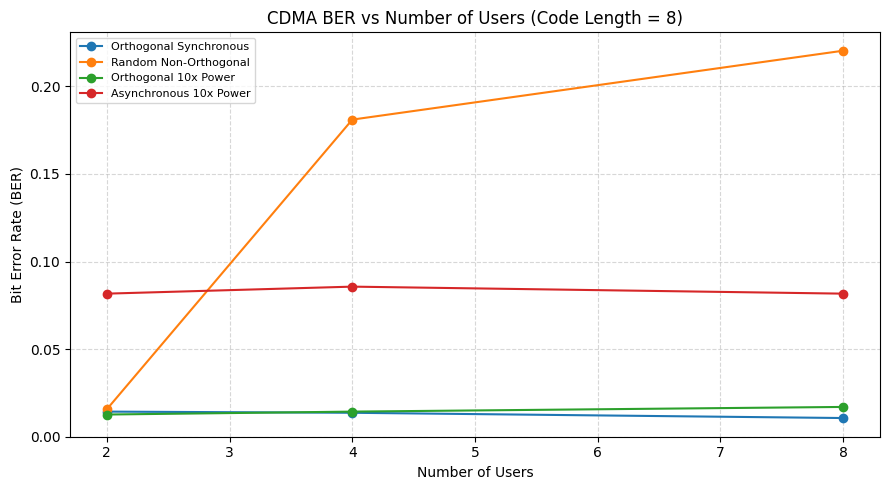

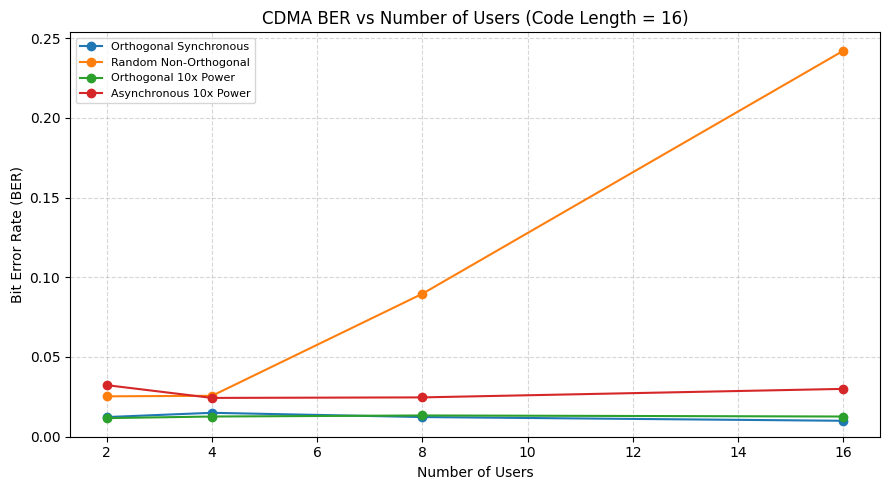

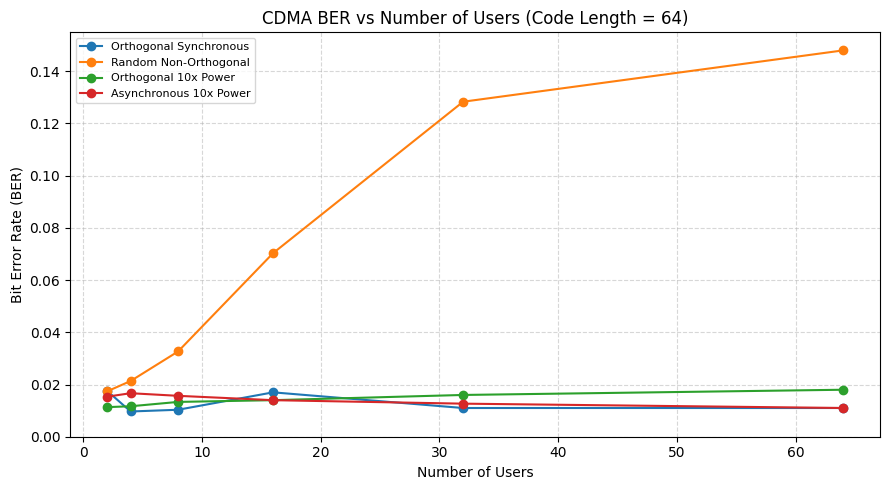

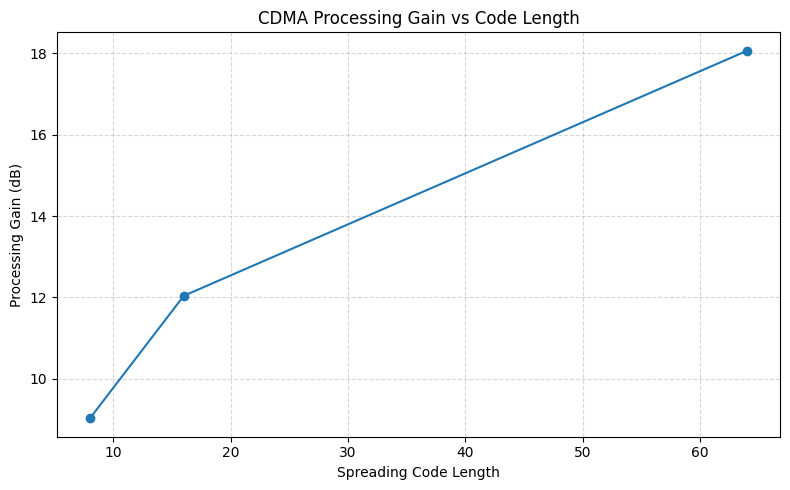


PROCESSING GAIN SUMMARY
Code Length:  8 | Processing Gain:  8 | Processing Gain (dB): 9.03 dB
Code Length: 16 | Processing Gain: 16 | Processing Gain (dB): 12.04 dB
Code Length: 64 | Processing Gain: 64 | Processing Gain (dB): 18.06 dB

All Question 3 simulations completed successfully!


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# QUESTION 3: CDMA - ORTHOGONALITY, SPREADING AND NEAR-FAR
# ==========================================================

RANDOM_SEED = 42
NUM_BITS = 3000
EBN0_DB = 4

rng = np.random.default_rng(RANDOM_SEED)

# ----------------------------------------------------------
# 1. GENERATE WALSH-HADAMARD CODES
# ----------------------------------------------------------

def hadamard_matrix(n):

    H = np.array([[1]])

    while H.shape[0] < n:
        H = np.block([
            [H, H],
            [H, -H]
        ])

    return H


# ----------------------------------------------------------
# 2. SIMULATION FUNCTION
# ----------------------------------------------------------

def simulate_cdma(codes, user_count, code_length,
                  condition, data_bits, random_generator):

    total_chips = NUM_BITS * code_length

    # Each user transmits BPSK data spread using its code
    received_signal = np.zeros(total_chips)

    # Noise power based on the selected Eb/N0
    ebn0 = 10 ** (EBN0_DB / 10)

    noise_std = np.sqrt(
        code_length / (2 * ebn0)
    )

    # Identify the high-power interfering user
    near_far = condition in [
        "Orthogonal 10x Power",
        "Asynchronous 10x Power"
    ]

    high_power_user = user_count - 1

    for user in range(user_count):

        # Spread each data bit across the code chips
        spread_signal = (
            data_bits[user, :, None] * codes[user]
        )

        # Convert the two-dimensional signal into a chip stream
        chip_stream = spread_signal.reshape(-1).astype(float)

        # Ten times power means sqrt(10) times amplitude
        if near_far and user == high_power_user:
            chip_stream *= np.sqrt(10)

        # Introduce a one-chip timing offset in the
        # asynchronous near-far experiment
        if (
            condition == "Asynchronous 10x Power"
            and user == high_power_user
        ):
            delayed_stream = np.zeros(total_chips)
            delayed_stream[1:] = chip_stream[:-1]
            chip_stream = delayed_stream

        received_signal += chip_stream

    # Add additive white Gaussian noise
    received_signal += random_generator.normal(
        0, noise_std, total_chips
    )

    # ------------------------------------------------------
    # 3. DESPREADING AT THE TARGET RECEIVER
    # ------------------------------------------------------

    received_blocks = received_signal.reshape(
        NUM_BITS, code_length
    )

    target_code = codes[0]

    # Correlation with the target spreading code
    decision_values = (
        received_blocks @ target_code
    ) / code_length

    # BPSK decision
    detected_bits = np.where(
        decision_values >= 0, 1, -1
    )

    original_bits = data_bits[0]

    # ------------------------------------------------------
    # 4. BIT ERROR RATE
    # ------------------------------------------------------

    bit_errors = np.sum(
        detected_bits != original_bits
    )

    ber = bit_errors / NUM_BITS

    # ------------------------------------------------------
    # 5. CODE CORRELATION
    # ------------------------------------------------------

    cross_correlations = []

    for user in range(1, user_count):

        correlation = abs(
            np.dot(target_code, codes[user])
        ) / code_length

        cross_correlations.append(correlation)

    max_cross_correlation = (
        max(cross_correlations)
        if cross_correlations else 0
    )

    # One-chip cyclic-shift correlation proxy
    shifted_correlations = []

    for user in range(1, user_count):

        shifted_code = np.roll(codes[user], 1)

        correlation = abs(
            np.dot(target_code, shifted_code)
        ) / code_length

        shifted_correlations.append(correlation)

    max_shifted_correlation = (
        max(shifted_correlations)
        if shifted_correlations else 0
    )

    # Processing gain
    processing_gain = code_length

    processing_gain_db = (
        10 * np.log10(processing_gain)
    )

    return {
        "Code Length": code_length,
        "Number of Users": user_count,
        "Condition": condition,
        "Total Bits": NUM_BITS,
        "Bit Errors": bit_errors,
        "BER": ber,
        "Max Cross Correlation": max_cross_correlation,
        "Max 1-Chip Shift Correlation": max_shifted_correlation,
        "Processing Gain": processing_gain,
        "Processing Gain (dB)": processing_gain_db,
        "Eb/N0 (dB)": EBN0_DB
    }


# ----------------------------------------------------------
# 6. RUN THREE REQUIRED CONDITIONS AND AN ASYNC EXTENSION
# ----------------------------------------------------------

code_lengths = [8, 16, 64]

conditions = [
    "Orthogonal Synchronous",
    "Random Non-Orthogonal",
    "Orthogonal 10x Power",
    "Asynchronous 10x Power"
]

results = []

for code_length in code_lengths:

    walsh_codes = hadamard_matrix(code_length)

    # User counts supported by each spreading-code length
    user_counts = [
        n for n in [2, 4, 8, 16, 32, 64]
        if n <= code_length
    ]

    for user_count in user_counts:

        # Use the same data bits across the conditions
        data_rng = np.random.default_rng(
            RANDOM_SEED + code_length * 100 + user_count
        )

        data_bits = data_rng.choice(
            [-1, 1],
            size=(user_count, NUM_BITS)
        )

        # Generate random non-orthogonal spreading codes
        code_rng = np.random.default_rng(
            RANDOM_SEED + code_length + user_count
        )

        random_codes = code_rng.choice(
            [-1, 1],
            size=(user_count, code_length)
        )

        # Build the four experiments
        experiment_configs = [
            (
                "Orthogonal Synchronous",
                walsh_codes[:user_count]
            ),
            (
                "Random Non-Orthogonal",
                random_codes
            ),
            (
                "Orthogonal 10x Power",
                walsh_codes[:user_count]
            ),
            (
                "Asynchronous 10x Power",
                walsh_codes[:user_count]
            )
        ]

        for condition, selected_codes in experiment_configs:

            experiment_rng = np.random.default_rng(
                RANDOM_SEED
                + code_length * 1000
                + user_count * 10
                + conditions.index(condition)
            )

            result = simulate_cdma(
                selected_codes,
                user_count,
                code_length,
                condition,
                data_bits,
                experiment_rng
            )

            results.append(result)


# ----------------------------------------------------------
# 7. DISPLAY EXPERIMENTAL RESULTS
# ----------------------------------------------------------

results_df = pd.DataFrame(results)

print("=" * 90)
print("CDMA SPREADING, DESPREADING AND NEAR-FAR SIMULATION")
print("=" * 90)

print(results_df.round(5).to_string(index=False))


# ----------------------------------------------------------
# 8. SAVE CSV DATA
# ----------------------------------------------------------

results_df.to_csv(
    "q3_cdma_results.csv",
    index=False
)

print("\nCSV file generated: q3_cdma_results.csv")


# ----------------------------------------------------------
# 9. GRAPH: BER VS NUMBER OF USERS
# ----------------------------------------------------------

for code_length in code_lengths:

    subset = results_df[
        results_df["Code Length"] == code_length
    ]

    plt.figure(figsize=(9, 5))

    for condition in conditions:

        condition_data = subset[
            subset["Condition"] == condition
        ]

        plt.plot(
            condition_data["Number of Users"],
            condition_data["BER"],
            marker="o",
            label=condition
        )

    plt.xlabel("Number of Users")
    plt.ylabel("Bit Error Rate (BER)")
    plt.title(
        f"CDMA BER vs Number of Users "
        f"(Code Length = {code_length})"
    )

    plt.ylim(bottom=0)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(fontsize=8)
    plt.tight_layout()

    filename = f"q3_ber_code_length_{code_length}.png"

    plt.savefig(filename, dpi=300)
    plt.show()


# ----------------------------------------------------------
# 10. GRAPH: PROCESSING GAIN
# ----------------------------------------------------------

processing_gain = [
    10 * np.log10(length)
    for length in code_lengths
]

plt.figure(figsize=(8, 5))

plt.plot(
    code_lengths,
    processing_gain,
    marker="o"
)

plt.xlabel("Spreading Code Length")
plt.ylabel("Processing Gain (dB)")
plt.title("CDMA Processing Gain vs Code Length")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "q3_processing_gain.png",
    dpi=300
)

plt.show()


# ----------------------------------------------------------
# 11. DISPLAY A SUMMARY
# ----------------------------------------------------------

print("\nPROCESSING GAIN SUMMARY")

for length in code_lengths:

    gain_db = 10 * np.log10(length)

    print(
        f"Code Length: {length:2d} | "
        f"Processing Gain: {length:2d} | "
        f"Processing Gain (dB): {gain_db:.2f} dB"
    )

print("\nAll Question 3 simulations completed successfully!")


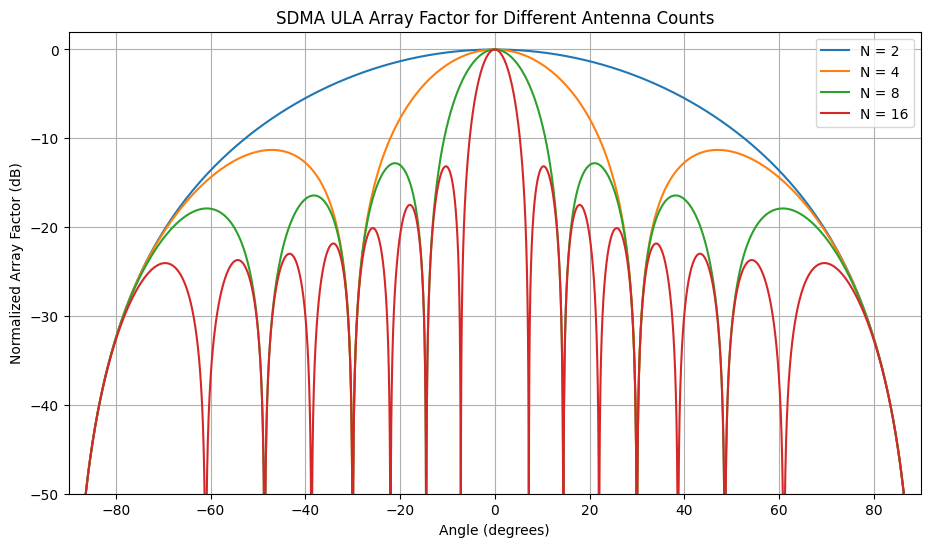


QUESTION 5 RESULTS
 Antenna Elements  Beamwidth (degrees)  Maximum Sidelobe Level (dB)  Interferer Angle (degrees)  Interference Rejection (dB)
                2               60.000                     -160.000                          30                         3.01
                4               26.323                      -11.303                          30                       160.00
                8               12.803                      -12.797                          30                       160.00
               16                6.359                      -13.147                          30                       160.00


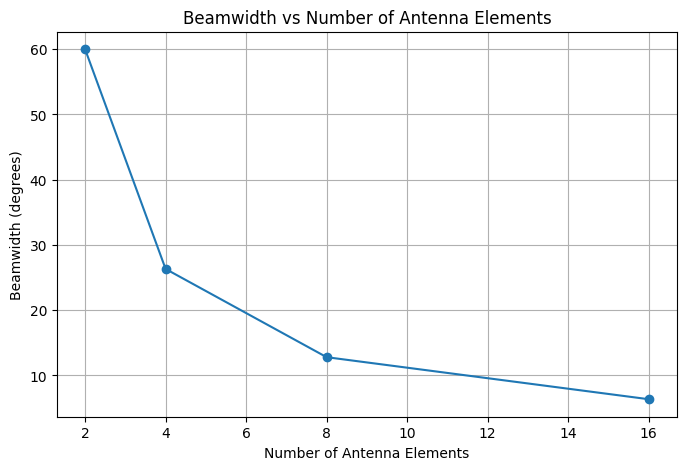


Files generated:
1. q5_sdma_results.csv
2. q5_ula_array_factor.png
3. q5_beamwidth.png


In [4]:

# QUESTION 5: SDMA - ULA ARRAY FACTOR ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fixed parameters
ANTENNA_COUNTS = [2, 4, 8, 16]
D_OVER_LAMBDA = 0.5
DESIRED_ANGLE = 0
INTERFERER_ANGLE = 30
ANGLES = np.linspace(-90, 90, 36001)

def calculate_array_factor(num_elements, angles):
    """Calculate normalized broadside ULA array factor."""
    theta = np.radians(angles)
    phase = 2 * np.pi * D_OVER_LAMBDA * np.sin(theta)

    n = np.arange(num_elements)
    weights = np.ones(num_elements)

    steering = np.exp(
        1j * np.outer(np.sin(theta), 2 * np.pi *
                      D_OVER_LAMBDA * n)
    )

    response = steering @ weights
    response = np.abs(response) / num_elements

    return response

def find_beamwidth(angles, response):
    """Find approximate half-power beamwidth."""
    power = response ** 2
    peak_index = np.argmax(power)
    half_power = 0.5

    left_candidates = np.where(
        power[:peak_index] <= half_power
    )[0]

    right_candidates = np.where(
        power[peak_index + 1:] <= half_power
    )[0]

    if len(left_candidates) == 0 or len(right_candidates) == 0:
        return np.nan

    left_index = left_candidates[-1]
    right_index = peak_index + 1 + right_candidates[0]

    left_angle = np.interp(
        half_power,
        [power[left_index], power[left_index + 1]],
        [angles[left_index], angles[left_index + 1]]
    )

    right_angle = np.interp(
        half_power,
        [power[right_index], power[right_index - 1]],
        [angles[right_index], angles[right_index - 1]]
    )

    return right_angle - left_angle

results = []
plt.figure(figsize=(11, 6))

for n in ANTENNA_COUNTS:
    af = calculate_array_factor(n, ANGLES)
    power_db = 20 * np.log10(np.maximum(af, 1e-8))

    beamwidth = find_beamwidth(ANGLES, af)

    # Approximate first-null region in direction-cosine space
    u = np.sin(np.radians(ANGLES))
    main_lobe_mask = np.abs(u) < (2 / n)

    sidelobe_values = af[~main_lobe_mask]

    if len(sidelobe_values) > 0:
        sidelobe_level = 20 * np.log10(
            max(np.max(sidelobe_values), 1e-8)
        )
    else:
        sidelobe_level = np.nan

    # Array response towards an interferer at 30 degrees
    interferer_response = calculate_array_factor(
        n, np.array([INTERFERER_ANGLE])
    )[0]

    # Desired broadside response is normalized to 1
    interference_rejection = -20 * np.log10(
        max(interferer_response, 1e-8)
    )

    results.append({
        "Antenna Elements": n,
        "Beamwidth (degrees)": beamwidth,
        "Maximum Sidelobe Level (dB)": sidelobe_level,
        "Interferer Angle (degrees)": INTERFERER_ANGLE,
        "Interference Rejection (dB)": interference_rejection
    })

    plt.plot(ANGLES, power_db, label=f"N = {n}")

plt.title("SDMA ULA Array Factor for Different Antenna Counts")
plt.xlabel("Angle (degrees)")
plt.ylabel("Normalized Array Factor (dB)")
plt.ylim(-50, 2)
plt.xlim(-90, 90)
plt.grid(True)
plt.legend()
plt.savefig("q5_ula_array_factor.png", dpi=300)
plt.show()

results_df = pd.DataFrame(results)
print("\nQUESTION 5 RESULTS")
print(results_df.round(3).to_string(index=False))

results_df.to_csv("q5_sdma_results.csv", index=False)

# Separate beamwidth graph
plt.figure(figsize=(8, 5))
plt.plot(
    results_df["Antenna Elements"],
    results_df["Beamwidth (degrees)"],
    marker="o"
)
plt.title("Beamwidth vs Number of Antenna Elements")
plt.xlabel("Number of Antenna Elements")
plt.ylabel("Beamwidth (degrees)")
plt.grid(True)
plt.savefig("q5_beamwidth.png", dpi=300)
plt.show()

print("\nFiles generated:")
print("1. q5_sdma_results.csv")
print("2. q5_ula_array_factor.png")
print("3. q5_beamwidth.png")


TECHNOLOGY SCORE MATRIX
       Capacity  Mobility  Interference Handling  Implementation Simplicity  \
SDMA          5         3                      4                          2   
TDMA          2         4                      3                          5   
FDMA          2         4                      3                          4   
CDMA          4         5                      4                          3   
OFDMA         5         4                      5                          3   

       Coverage and Cost  
SDMA                   3  
TDMA                   4  
FDMA                   4  
CDMA                   4  
OFDMA                  4  

WEIGHTED COMPARISON RESULTS
        Deployment Technology  Weighted Score
    Campus Hotspot       SDMA           3.778
    Campus Hotspot       TDMA           3.222
    Campus Hotspot       FDMA           3.111
    Campus Hotspot       CDMA           4.000
    Campus Hotspot      OFDMA           4.444
   Rural Macrocell       SDMA     

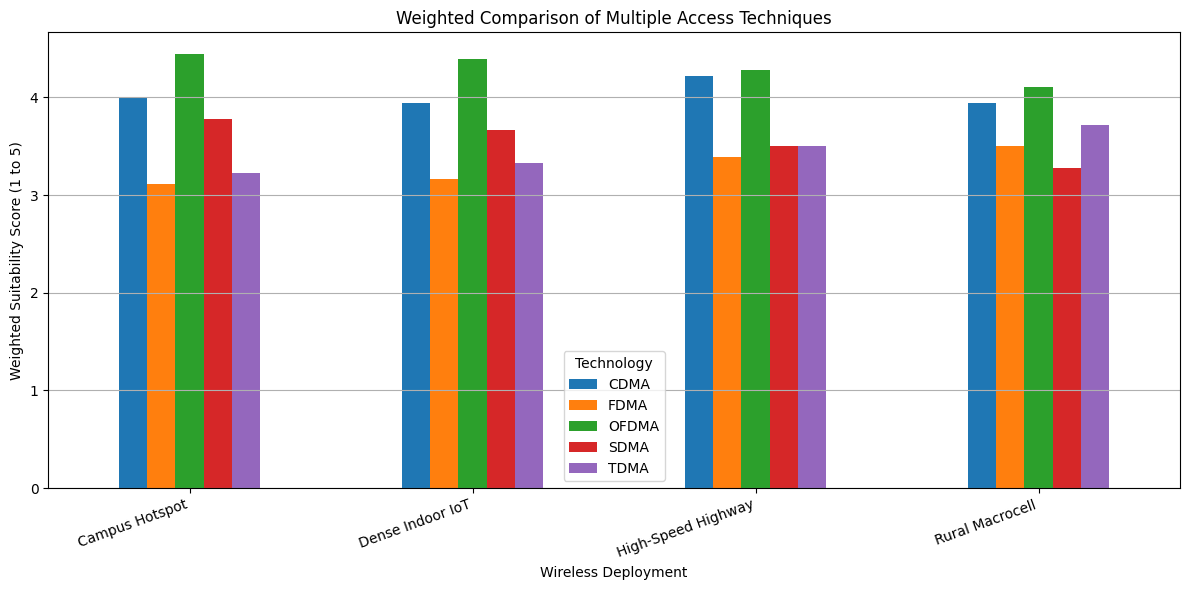


SENSITIVITY ANALYSIS (+/-20% WEIGHT PERTURBATION)
        Deployment Technology  Winning Percentage
    Campus Hotspot       SDMA                 0.0
    Campus Hotspot       TDMA                 0.0
    Campus Hotspot       FDMA                 0.0
    Campus Hotspot       CDMA                 0.0
    Campus Hotspot      OFDMA               100.0
   Rural Macrocell       SDMA                 0.0
   Rural Macrocell       TDMA                 0.0
   Rural Macrocell       FDMA                 0.0
   Rural Macrocell       CDMA                 0.0
   Rural Macrocell      OFDMA               100.0
High-Speed Highway       SDMA                 0.0
High-Speed Highway       TDMA                 0.0
High-Speed Highway       FDMA                 0.0
High-Speed Highway       CDMA                15.1
High-Speed Highway      OFDMA                84.9
  Dense Indoor IoT       SDMA                 0.0
  Dense Indoor IoT       TDMA                 0.0
  Dense Indoor IoT       FDMA                 0.0

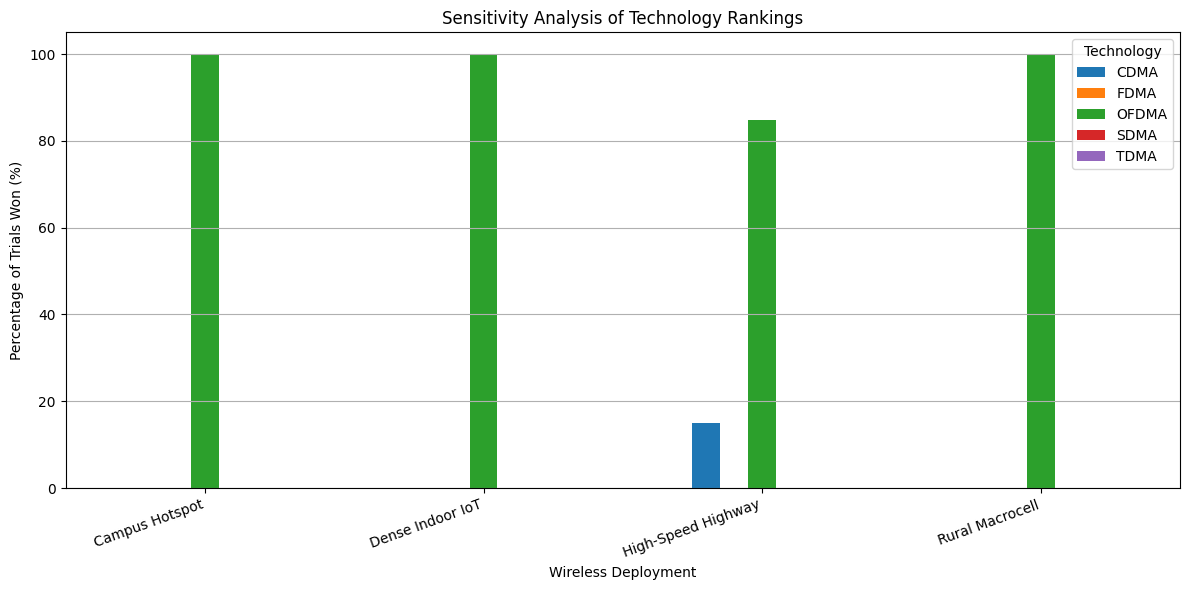


Files generated:
1. q6_weighted_comparison.csv
2. q6_sensitivity_analysis.csv
3. q6_weighted_comparison.png
4. q6_sensitivity_analysis.png


In [5]:

# QUESTION 6: WEIGHTED COMPARISON OF MULTIPLE ACCESS TECHNIQUES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

technologies = ["SDMA", "TDMA", "FDMA", "CDMA", "OFDMA"]

criteria = [
    "Capacity",
    "Mobility",
    "Interference Handling",
    "Implementation Simplicity",
    "Coverage and Cost"
]

# Scores are on a scale of 1 to 5.
# Higher scores indicate better suitability.
scores = {
    "SDMA":  [5, 3, 4, 2, 3],
    "TDMA":  [2, 4, 3, 5, 4],
    "FDMA":  [2, 4, 3, 4, 4],
    "CDMA":  [4, 5, 4, 3, 4],
    "OFDMA": [5, 4, 5, 3, 4]
}

# Deployment-specific criterion weights
deployments = {
    "Campus Hotspot": [0.30, 0.10, 0.20, 0.10, 0.20],
    "Rural Macrocell": [0.15, 0.15, 0.15, 0.20, 0.25],
    "High-Speed Highway": [0.20, 0.30, 0.15, 0.10, 0.15],
    "Dense Indoor IoT": [0.25, 0.10, 0.25, 0.15, 0.15]
}

# Normalize weights so that each deployment totals 1
for name in deployments:
    weights = np.array(deployments[name], dtype=float)
    deployments[name] = weights / weights.sum()

score_table = pd.DataFrame(scores, index=criteria).T

print("TECHNOLOGY SCORE MATRIX")
print(score_table)

# Calculate weighted scores
comparison_rows = []

for deployment, weights in deployments.items():
    for technology in technologies:
        technology_scores = np.array(scores[technology])
        total_score = np.sum(technology_scores * weights)

        comparison_rows.append({
            "Deployment": deployment,
            "Technology": technology,
            "Weighted Score": total_score
        })

comparison_df = pd.DataFrame(comparison_rows)

print("\nWEIGHTED COMPARISON RESULTS")
print(comparison_df.round(3).to_string(index=False))

comparison_df.to_csv(
    "q6_weighted_comparison.csv", index=False
)

# Plot weighted scores
pivot = comparison_df.pivot(
    index="Deployment",
    columns="Technology",
    values="Weighted Score"
)

pivot.plot(kind="bar", figsize=(12, 6))
plt.title("Weighted Comparison of Multiple Access Techniques")
plt.xlabel("Wireless Deployment")
plt.ylabel("Weighted Suitability Score (1 to 5)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
plt.legend(title="Technology")
plt.tight_layout()
plt.savefig("q6_weighted_comparison.png", dpi=300)
plt.show()

# Sensitivity analysis:
# Perturb each original weight independently by up to +/-20%.
# Normalize the perturbed weights before scoring.
NUM_TRIALS = 5000

sensitivity_rows = []

for deployment, original_weights in deployments.items():

    win_counts = {tech: 0 for tech in technologies}

    for trial in range(NUM_TRIALS):

        perturbation = np.random.uniform(
            0.8, 1.2, len(criteria)
        )

        new_weights = original_weights * perturbation
        new_weights = new_weights / new_weights.sum()

        trial_scores = {}

        for technology in technologies:
            trial_scores[technology] = np.sum(
                np.array(scores[technology]) * new_weights
            )

        winner = max(trial_scores, key=trial_scores.get)
        win_counts[winner] += 1

    for technology in technologies:
        sensitivity_rows.append({
            "Deployment": deployment,
            "Technology": technology,
            "Winning Percentage": (
                win_counts[technology] / NUM_TRIALS
            ) * 100
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)

print("\nSENSITIVITY ANALYSIS (+/-20% WEIGHT PERTURBATION)")
print(sensitivity_df.round(2).to_string(index=False))

sensitivity_df.to_csv(
    "q6_sensitivity_analysis.csv", index=False
)

# Plot sensitivity results
sensitivity_pivot = sensitivity_df.pivot(
    index="Deployment",
    columns="Technology",
    values="Winning Percentage"
)

sensitivity_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Sensitivity Analysis of Technology Rankings")
plt.xlabel("Wireless Deployment")
plt.ylabel("Percentage of Trials Won (%)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
plt.legend(title="Technology")
plt.tight_layout()
plt.savefig("q6_sensitivity_analysis.png", dpi=300)
plt.show()

print("\nFiles generated:")
print("1. q6_weighted_comparison.csv")
print("2. q6_sensitivity_analysis.csv")
print("3. q6_weighted_comparison.png")
print("4. q6_sensitivity_analysis.png")


QUESTION 7: AVERAGE PERFORMANCE
Max Channel Sum Throughput              116.5828
Proportional Fair Sum Throughput        108.3027
Max Channel Jain Fairness                 0.8980
Proportional Fair Jain Fairness           0.9808
Max Channel Minimum User Rate             7.5477
Proportional Fair Minimum User Rate      10.7817
Max Channel Users Below Target            0.0000
Proportional Fair Users Below Target      0.0000


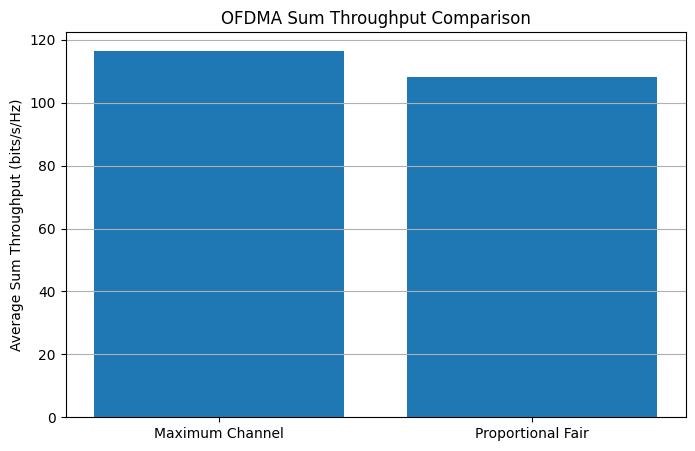

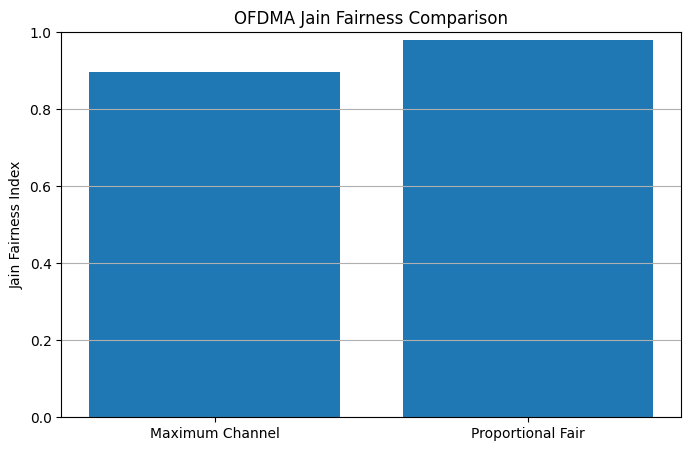

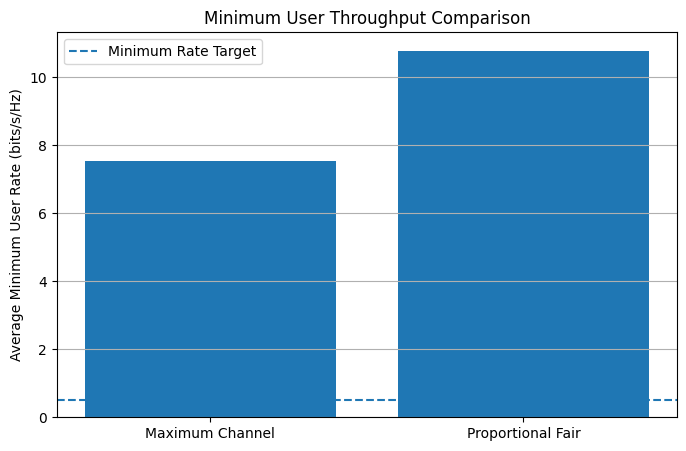


VALIDATION USING 1000 CHANNEL REALIZATIONS
Max Channel Sum Throughput: 116.5828 +/- 0.2192
Proportional Fair Sum Throughput: 108.3027 +/- 0.2378
Max Channel Jain Fairness: 0.8980 +/- 0.0029
Proportional Fair Jain Fairness: 0.9808 +/- 0.0006

Files generated:
1. q7_ofdma_validation_raw.csv
2. q7_ofdma_validation_summary.csv
3. q7_throughput_comparison.png
4. q7_fairness_comparison.png
5. q7_minimum_user_rate.png


In [6]:

# QUESTION 7: OFDMA LIMITATION, REDESIGN AND VALIDATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fixed simulation parameters
np.random.seed(42)

NUM_USERS = 8
NUM_SUBCARRIERS = 64
NUM_REALIZATIONS = 1000
NOISE_POWER = 1.0
MIN_RATE_TARGET = 0.5

# Store results for every channel realization
results = []

def jain_fairness(values):
    """Calculate Jain's fairness index."""
    values = np.array(values, dtype=float)

    numerator = np.sum(values) ** 2
    denominator = len(values) * np.sum(values ** 2)

    if denominator == 0:
        return 0

    return numerator / denominator

for realization in range(NUM_REALIZATIONS):

    # Frequency-selective fading channel
    # Each user has a different channel gain on each subcarrier
    channel = np.random.exponential(
        scale=1.0,
        size=(NUM_USERS, NUM_SUBCARRIERS)
    )

    # Shannon spectral efficiency for each user/subcarrier
    rates = np.log2(1 + channel / NOISE_POWER)

    # -------------------------------------------------
    # METHOD 1: MAXIMUM-CHANNEL / BEST-CHANNEL SCHEDULER
    # -------------------------------------------------

    # Each subcarrier is assigned to the user with
    # the highest instantaneous channel rate.
    best_user = np.argmax(rates, axis=0)

    max_channel_user_rates = np.zeros(NUM_USERS)

    for subcarrier in range(NUM_SUBCARRIERS):
        user = best_user[subcarrier]
        max_channel_user_rates[user] += rates[user, subcarrier]

    # -------------------------------------------------
    # METHOD 2: PROPORTIONAL-FAIR SCHEDULER
    # -------------------------------------------------

    # Select users based on channel rate divided by
    # their accumulated rate in this realization.
    fair_user_rates = np.zeros(NUM_USERS)

    for subcarrier in range(NUM_SUBCARRIERS):

        # Small positive value prevents division by zero
        metric = rates[:, subcarrier] / (
            fair_user_rates + 0.1
        )

        selected_user = np.argmax(metric)

        fair_user_rates[selected_user] += (
            rates[selected_user, subcarrier]
        )

    # Calculate performance indicators
    results.append({
        "Realization": realization + 1,

        "Max Channel Sum Throughput":
            np.sum(max_channel_user_rates),

        "Proportional Fair Sum Throughput":
            np.sum(fair_user_rates),

        "Max Channel Jain Fairness":
            jain_fairness(max_channel_user_rates),

        "Proportional Fair Jain Fairness":
            jain_fairness(fair_user_rates),

        "Max Channel Minimum User Rate":
            np.min(max_channel_user_rates),

        "Proportional Fair Minimum User Rate":
            np.min(fair_user_rates),

        "Max Channel Users Below Target":
            np.sum(max_channel_user_rates < MIN_RATE_TARGET),

        "Proportional Fair Users Below Target":
            np.sum(fair_user_rates < MIN_RATE_TARGET)
    })

results_df = pd.DataFrame(results)

# Display average performance
summary = results_df.drop(
    columns=["Realization"]
).mean()

print("QUESTION 7: AVERAGE PERFORMANCE")
print(summary.round(4).to_string())

results_df.to_csv(
    "q7_ofdma_validation_raw.csv", index=False
)

summary_df = summary.reset_index()
summary_df.columns = ["Metric", "Average Value"]

summary_df.to_csv(
    "q7_ofdma_validation_summary.csv", index=False
)

# -------------------------------------------------
# GRAPH 1: THROUGHPUT COMPARISON
# -------------------------------------------------

throughput_values = [
    results_df["Max Channel Sum Throughput"].mean(),
    results_df["Proportional Fair Sum Throughput"].mean()
]

plt.figure(figsize=(8, 5))
plt.bar(
    ["Maximum Channel", "Proportional Fair"],
    throughput_values
)
plt.title("OFDMA Sum Throughput Comparison")
plt.ylabel("Average Sum Throughput (bits/s/Hz)")
plt.grid(axis="y")
plt.savefig("q7_throughput_comparison.png", dpi=300)
plt.show()

# -------------------------------------------------
# GRAPH 2: FAIRNESS COMPARISON
# -------------------------------------------------

fairness_values = [
    results_df["Max Channel Jain Fairness"].mean(),
    results_df["Proportional Fair Jain Fairness"].mean()
]

plt.figure(figsize=(8, 5))
plt.bar(
    ["Maximum Channel", "Proportional Fair"],
    fairness_values
)
plt.title("OFDMA Jain Fairness Comparison")
plt.ylabel("Jain Fairness Index")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.savefig("q7_fairness_comparison.png", dpi=300)
plt.show()

# -------------------------------------------------
# GRAPH 3: MINIMUM USER RATE COMPARISON
# -------------------------------------------------

minimum_rates = [
    results_df["Max Channel Minimum User Rate"].mean(),
    results_df["Proportional Fair Minimum User Rate"].mean()
]

plt.figure(figsize=(8, 5))
plt.bar(
    ["Maximum Channel", "Proportional Fair"],
    minimum_rates
)
plt.axhline(
    MIN_RATE_TARGET,
    linestyle="--",
    label="Minimum Rate Target"
)
plt.title("Minimum User Throughput Comparison")
plt.ylabel("Average Minimum User Rate (bits/s/Hz)")
plt.legend()
plt.grid(axis="y")
plt.savefig("q7_minimum_user_rate.png", dpi=300)
plt.show()

# -------------------------------------------------
# VALIDATION: CONFIDENCE INTERVALS
# -------------------------------------------------

print("\nVALIDATION USING 1000 CHANNEL REALIZATIONS")

for column in [
    "Max Channel Sum Throughput",
    "Proportional Fair Sum Throughput",
    "Max Channel Jain Fairness",
    "Proportional Fair Jain Fairness"
]:

    mean_value = results_df[column].mean()
    std_value = results_df[column].std()

    # Approximate 95% confidence interval for the mean
    margin = 1.96 * std_value / np.sqrt(NUM_REALIZATIONS)

    print(
        f"{column}: {mean_value:.4f} "
        f"+/- {margin:.4f}"
    )

print("\nFiles generated:")
print("1. q7_ofdma_validation_raw.csv")
print("2. q7_ofdma_validation_summary.csv")
print("3. q7_throughput_comparison.png")
print("4. q7_fairness_comparison.png")
print("5. q7_minimum_user_rate.png")
